# Modelo de riesgo de accidentes graves en Madrid
**Proyecto end-to-end · capítulo 2 (modelado)** · Dario Guerrero Galán · MSMK University College

Los CSV anuales 2023–2025 van en `data/` (o `data/raw/`), junto a este archivo. Para reproducirlo: *Restart kernel and run all* (semillas fijas, `SEED = 42`).

## 0. Resumen ejecutivo
1. **Pregunta:** ¿en qué distritos, días y franjas de 6 horas debe reforzar la unidad de tráfico los controles cada lunes para cubrir más heridos graves con el mismo personal?
2. **Modelo:** Regresión logística, entrenado con 2023–2024 con historial de cada celda (distrito × tipo de día × franja) y calendario; se evalúa en 2025 y ordena las 336 celdas de cada semana.
3. **Mejora sobre la regla de puntos negros:** con 10 celdas por semana capta el 13.9 % de los graves, frente al 10.2 % de ir a los puntos negros y al 2.5 % de la rotación actual (azar) (diferencia +3.7 puntos, IC 95 % +1.1 a +6.4).
4. **Qué hacer:** no cambiar el procedimiento todavía: usar el modelo en paralelo (la evidencia es mixta: en validación cruzada captó 8.8 % frente a 12.8 % de los puntos negros) y decidir con los datos de 2026.
5. **Límite principal:** con 10 celdas el modelo capta solo el 13.9 % de los graves (ordena, no predice), el 47 % de sus elecciones cae en dos distritos, y solo hay tres años completos de registro policial; la mejora mide cobertura, no prevención.

## 1. Del brief a una tarea de ML

Cada lunes el responsable de planificación de la unidad de tráfico decide en qué distrito, día y franja concentra los controles preventivos, con plantilla fija. No necesita saber qué persona se lesionará, sino **dónde y cuándo es más probable que haya heridos graves o fallecidos esa semana**.

| Pregunta | Respuesta |
|---|---|
| Decisión que alimenta | Elegir cada lunes las 10 combinaciones distrito × día × franja donde reforzar controles (brief, §2.2 y §3.1). |
| Tipo de tarea | Clasificación binaria usada como **ranking**: la probabilidad ordena las celdas y se eligen las 10 primeras. |
| Objetivo | `y = 1` si la celda tiene al menos una persona con `cod_lesividad` 3 o 4 en la semana; si no, `y = 0`. |
| Grano | Distrito (21) × tipo de día (L–J, V, S, D) × franja de 6 h × semana: 336 celdas por semana. |
| Momento de la predicción | Lunes por la mañana, para esa semana. |
| Datos disponibles entonces | Historial de la celda hasta 4 semanas antes (el brief indica 1–2 meses de desfase) y calendario. Sin tiempo observado: el lunes solo hay previsión. |
| Regla actual a superar | **Rotación entre distritos** (supuesto de trabajo del brief, §2.1). No hay datos de cómo rota, así que se simula con el azar. Añado una regla más exigente, "puntos negros": ir a donde más graves se han acumulado. |
| Métrica | **Captura@10**: % de los graves de la semana que caen en las 10 celdas elegidas; apoyada en precisión@10 y AP. |
| Traducción al negocio | Más graves "cubiertos" con la misma plantilla; apoya el KPI principal, el índice de gravedad. |

**Qué ha cambiado respecto al brief.**
- El brief hablaba de distrito × día de la semana × franja. Agrupo lunes–jueves porque con 7 días muchas celdas quedarían casi siempre vacías.
- El objetivo sigue siendo persona grave o fallecida (1,1 % de filas), pero lo agrego por celda: es el nivel de la decisión y evita señalar a individuos.
- Meteorología, festivos y padrón aún no están unidos, así que H4 solo se contrasta a medias. Dejo 2026 para monitorizar, como en el brief.

In [1]:
import re, sys, json, time, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import joblib, sklearn
from IPython.display import Markdown, display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.base import clone

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)

# ---- Parámetros del proyecto (todo lo que se puede cambiar está aquí) ----
DATA_DIR = next((p for p in (Path("data/raw"), Path("data")) if list(p.glob("*.csv"))), Path("data"))  # ruta relativa al notebook
FIRST_YEAR, LAST_YEAR = 2023, 2025  # 2026 se reserva para monitorización (bloque 4)
GAP_WEEKS = 4        # retraso del dato: el lunes t solo se conoce hasta la semana t-4
WARMUP_WEEKS = 26    # semanas iniciales sin historial suficiente, fuera del modelado
TOP_K = 10           # celdas que el planificador puede cubrir cada semana
VAL_START, TEST_START = "2024-07-01", "2025-01-01"
import plotly.io as pio
try:   # kaleido (pip install kaleido) guarda cada gráfico también como imagen, para verlo en GitHub sin ejecutar el notebook
    import kaleido  # noqa: F401
    pio.renderers.default = "plotly_mimetype+png"
except ImportError:
    print("Aviso: sin kaleido los gráficos son interactivos pero no se ven en la vista previa de GitHub.")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


## 2. Datos y calidad

**Ficha del dataset.** *Accidentes de tráfico de la ciudad de Madrid (detalle por persona)*, Policía Municipal, CC BY 4.0, descargado el 21/10/2026. Cada fila es una persona implicada; las filas con el mismo `num_expediente` son un accidente. Uso 2023–2025: unas 149.200 filas de las 182.559 del total y 19 columnas. Problemas del brief: lesividad vacía en el 45 %, meteorología con erratas, 4,1 % de filas idénticas y coordenadas con coma decimal en 2026.

**Limpieza y motivo.**
- Leo todo como texto y convierto después, para que los formatos mezclados no rompan la carga.
- **Conservo las filas idénticas** y solo las cuento: pueden ser personas distintas (dos pasajeros de la misma edad), como advierte el brief.
- Descarto filas sin fecha válida, fuera de 2023–2025, con hora fuera de 0–23 o distrito fuera de 1–21. Uso el código de distrito, no el nombre.
- **Recodifico la lesividad:** vacía o `NULL` significa "sin asistencia sanitaria", igual que el código 14. Son personas sin lesión atendida: ni víctimas ni graves.

In [2]:
def norm(s):
    # minúsculas, sin tildes, sin espacios ni símbolos: 'Estado meteorológico' -> 'estado_meteorologico'
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().strip().lower()
    return re.sub(r"\W+", "_", s).strip("_")

def read_any(path):
    for enc in ("utf-8-sig", "latin-1"):
        try:
            d = pd.read_csv(path, sep=";", encoding=enc, dtype=str)
            if d.shape[1] == 1:                       # por si algún año viene separado por comas
                d = pd.read_csv(path, sep=",", encoding=enc, dtype=str)
            return d
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No puedo leer {path}")

files = sorted(DATA_DIR.glob("*.csv"))
if not files:
    raise FileNotFoundError("Copia los CSV anuales del dataset (2023, 2024, 2025) en project/data/ o project/data/raw/.")
frames = []
for f in files:
    d = read_any(f)
    d.columns = [norm(c) for c in d.columns]
    d["fichero"] = f.name
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)

needed = ["num_expediente", "fecha", "hora", "cod_distrito", "tipo_persona", "tipo_vehiculo",
          "rango_edad", "cod_lesividad", "estado_meteorologico", "positiva_alcohol", "positiva_droga"]
missing = [c for c in needed if c not in raw.columns]
assert not missing, f"Faltan columnas en el dataset: {missing}. Columnas disponibles: {list(raw.columns)}"
print("Ficheros leídos:", [f.name for f in files])
print(f"Filas cargadas: {len(raw):,} | columnas: {raw.shape[1]}")

Ficheros leídos: ['2023.csv', '2024.csv', '2025.csv']
Filas cargadas: 149,237 | columnas: 20


,filas
filas cargadas,149237
filas idénticas (se conservan: pueden ser personas distintas),6147
sin fecha válida,0
fuera de 2023-2025 (p. ej. 2026),0
hora inválida,0
distrito inválido,3
lesividad vacía o NULL (= sin asistencia sanitaria; no es víctima),67505
filas finales,149234


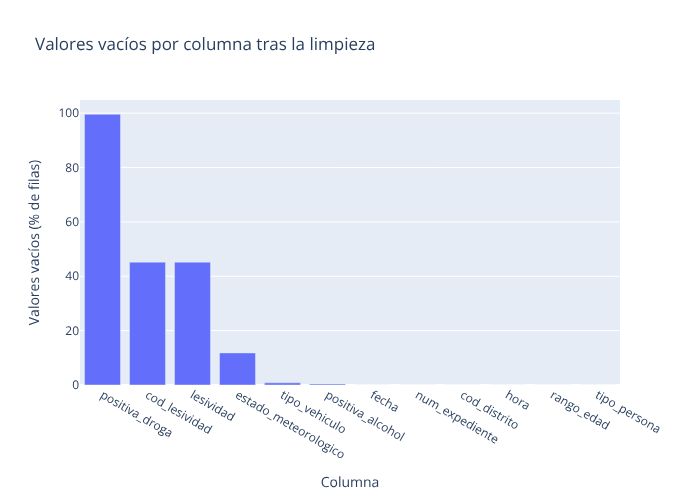

Personas con lesividad grave o fatal: 1,678 (1.12 % de las filas)


In [3]:
log = {"filas cargadas": len(raw)}

df = raw.copy()
log["filas idénticas (se conservan: pueden ser personas distintas)"] = int(raw.duplicated(subset=[c for c in raw.columns if c != "fichero"]).sum())

df["fecha"] = pd.to_datetime(df["fecha"], format="mixed", dayfirst=True, errors="coerce")
n = len(df); df = df[df["fecha"].notna()]; log["sin fecha válida"] = n - len(df)

n = len(df); df = df[df["fecha"].dt.year.between(FIRST_YEAR, LAST_YEAR)]
log[f"fuera de {FIRST_YEAR}-{LAST_YEAR} (p. ej. 2026)"] = n - len(df)

df["hora_int"] = pd.to_numeric(df["hora"].astype(str).str.extract(r"^\s*(\d{1,2})")[0], errors="coerce")
n = len(df); df = df[df["hora_int"].between(0, 23)]; log["hora inválida"] = n - len(df)

df["cod_distrito"] = pd.to_numeric(df["cod_distrito"], errors="coerce")
n = len(df); df = df[df["cod_distrito"].between(1, 21)]; log["distrito inválido"] = n - len(df)
df["cod_distrito"] = df["cod_distrito"].astype(int)
df["hora_int"] = df["hora_int"].astype(int)

df["lesividad"] = pd.to_numeric(df["cod_lesividad"], errors="coerce")
log["lesividad vacía o NULL (= sin asistencia sanitaria; no es víctima)"] = int(df["lesividad"].isna().sum())
log["filas finales"] = len(df)

df["es_victima"] = df["lesividad"].isin([1, 2, 3, 4, 5, 6, 7])
df["es_grave"] = df["lesividad"].isin([3, 4])
txt = lambda s: s.fillna("").map(norm)
df["persona_n"], df["vehiculo_n"], df["meteo_n"] = txt(df["tipo_persona"]), txt(df["tipo_vehiculo"]), txt(df["estado_meteorologico"])
df["edad_min"] = pd.to_numeric(df["rango_edad"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
positivo = lambda s: s.fillna("").map(norm).isin(["s", "si", "1", "positivo", "p"])
df["pos_alcohol_droga"] = positivo(df["positiva_alcohol"]) | positivo(df["positiva_droga"])
df["dow"] = df["fecha"].dt.dayofweek

display(pd.Series(log, name="filas").to_frame())
nulos = (df[needed + ["lesividad"]].isna().mean() * 100).round(1).sort_values(ascending=False)
fig = px.bar(nulos.reset_index(), x="index", y=0, title="Valores vacíos por columna tras la limpieza",
             labels={"index": "Columna", "0": "Valores vacíos (% de filas)"})
fig.update_layout(yaxis_title="Valores vacíos (% de filas)", xaxis_title="Columna"); fig.show()
print(f"Personas con lesividad grave o fatal: {int(df.es_grave.sum()):,} ({df.es_grave.mean()*100:.2f} % de las filas)")

### Qué significa para el planificador
Los datos se han limpiado con reglas simples y trazables; la tabla de arriba dice cuántas filas se descartan y por qué. Un detalle clave: la lesividad vacía **no es un dato perdido**, significa "sin asistencia sanitaria", así que esas personas no cuentan como víctimas. Los graves que aparecen son los registrados por la Policía Municipal.

## 3. Qué mostró la exploración

Construyo la **tabla de celdas** (el grano de la sección 1) y miro cómo se reparte el objetivo. Casi todas las celdas serán ceros: las clases están muy desequilibradas, por lo que la exactitud global no sirve como métrica.

53,088 celdas-semana (158 semanas × 336 celdas). Celdas con al menos un herido grave: 2.86 %


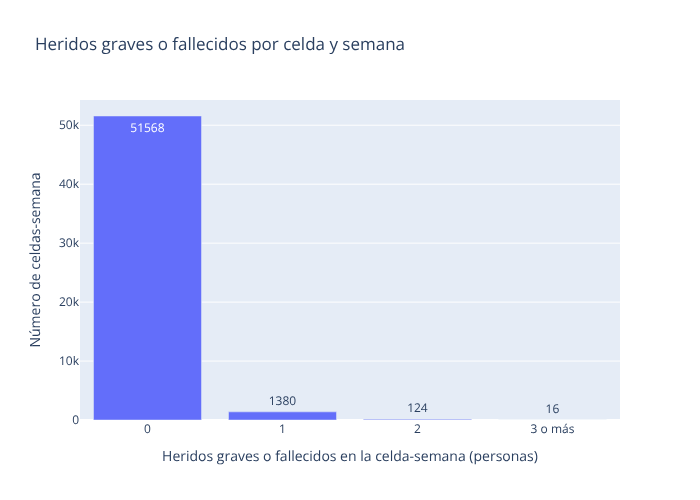

In [4]:
SLOT_LABELS = ["00-06", "06-12", "12-18", "18-24"]
df["franja"] = pd.cut(df["hora_int"], bins=[-1, 5, 11, 17, 23], labels=SLOT_LABELS).astype(str)
df["tipo_dia"] = df["dow"].map({0: "L-J", 1: "L-J", 2: "L-J", 3: "L-J", 4: "V", 5: "S", 6: "D"})
df["semana"] = df["fecha"].dt.to_period("W-SUN").dt.start_time       # lunes de cada semana

keys = ["semana", "cod_distrito", "tipo_dia", "franja"]
agg = df.groupby(keys).agg(
    accidentes=("num_expediente", "nunique"),
    victimas=("es_victima", "sum"),
    graves=("es_grave", "sum"),
).join(df[df["persona_n"].str.contains("peaton")].groupby(keys)["es_grave"].sum().rename("graves_peaton")).fillna(0)

semanas = pd.date_range(df["semana"].min(), df["semana"].max(), freq="W-MON")
grid = pd.MultiIndex.from_product([semanas, sorted(df["cod_distrito"].unique()), ["L-J", "V", "S", "D"], SLOT_LABELS], names=keys)
cells = agg.reindex(grid, fill_value=0).reset_index()
cells[["accidentes", "victimas", "graves", "graves_peaton"]] = cells[["accidentes", "victimas", "graves", "graves_peaton"]].astype(int)
cells["y"] = (cells["graves"] > 0).astype(int)
print(f"{len(cells):,} celdas-semana ({len(semanas)} semanas × {cells.groupby('semana').size().iloc[0]} celdas). "
      f"Celdas con al menos un herido grave: {cells.y.mean()*100:.2f} %")

dist = cells["graves"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 o más"}).value_counts().reindex(["0", "1", "2", "3 o más"])
fig = px.bar(x=dist.index, y=dist.values, text=dist.values, title="Heridos graves o fallecidos por celda y semana",
             labels={"x": "Heridos graves o fallecidos en la celda-semana (personas)", "y": "Número de celdas-semana"})
fig.show()

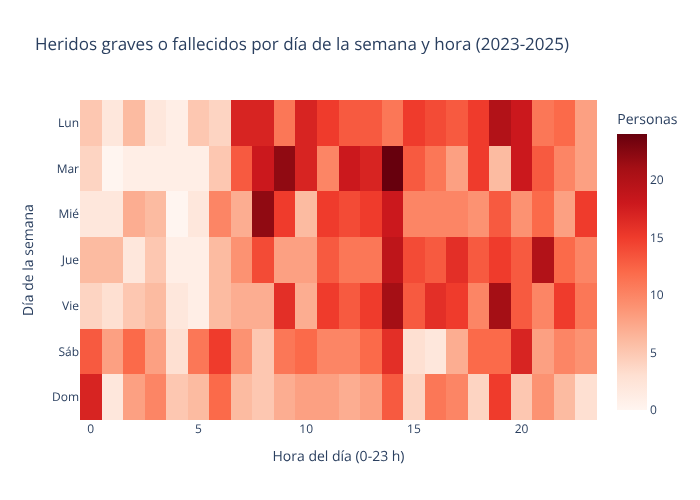

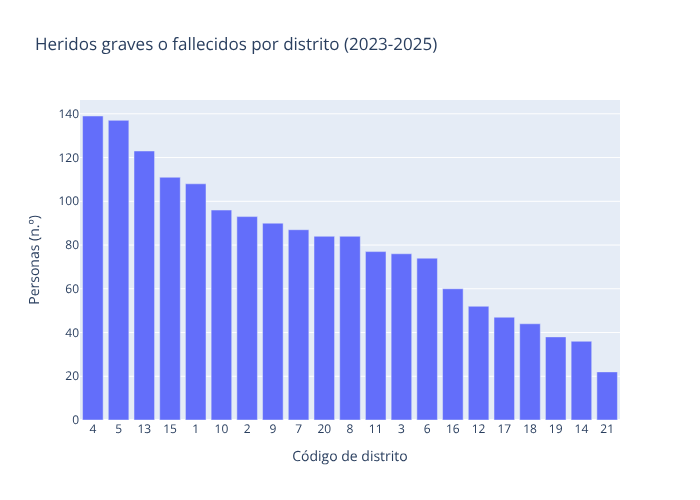

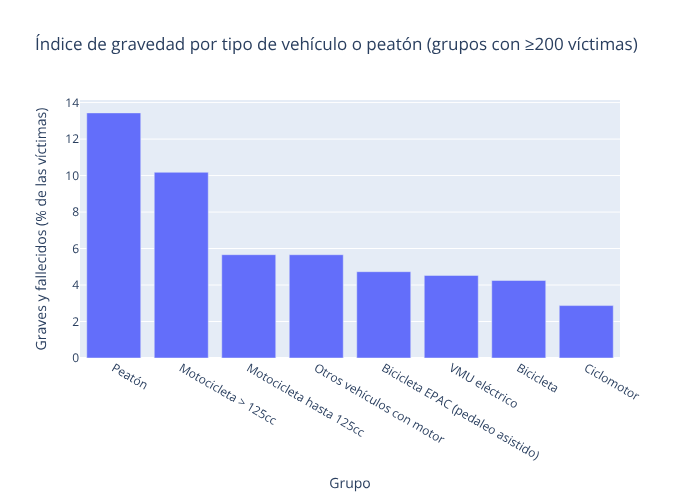

In [5]:
# Gráfico 1: ¿cuándo ocurren los graves? (día de la semana × hora)
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
h = df[df.es_grave].groupby(["dow", "hora_int"]).size().unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0)
fig = px.imshow(h.values, x=list(range(24)), y=dias, aspect="auto", color_continuous_scale="Reds",
                title="Heridos graves o fallecidos por día de la semana y hora (2023-2025)",
                labels={"x": "Hora del día (0-23 h)", "y": "Día de la semana", "color": "Personas"})
fig.show()

# Gráfico 2: graves por distrito
gd = df[df.es_grave].groupby("cod_distrito").size().sort_values(ascending=False)
fig = px.bar(x=gd.index.astype(str), y=gd.values, title="Heridos graves o fallecidos por distrito (2023-2025)",
             labels={"x": "Código de distrito", "y": "Personas (n.º)"})
fig.show()

# Gráfico 3: índice de gravedad por tipo de vehículo / persona
sev = (df[df.es_victima].assign(grupo=lambda d: np.where(d.persona_n.str.contains("peaton"), "Peatón", d.tipo_vehiculo.fillna("Desconocido")))
       .groupby("grupo").agg(victimas=("es_victima", "sum"), graves=("es_grave", "sum")))
sev = sev[sev.victimas >= 200].assign(indice=lambda d: d.graves / d.victimas * 100).sort_values("indice", ascending=False).head(8)
fig = px.bar(sev.reset_index(), x="grupo", y="indice", title="Índice de gravedad por tipo de vehículo o peatón (grupos con ≥200 víctimas)",
             labels={"grupo": "Grupo", "indice": "Graves y fallecidos (% de las víctimas)"})
fig.show()

In [6]:
# Contraste de las hipótesis del brief con el propio dataset
def sev_idx(d): return d.es_grave.sum() / max(d.es_victima.sum(), 1)
rows = []

# H1: positivos en alcohol/drogas concentrados en noches de V-S y pocos distritos
cond = df[df.persona_n.str.contains("conductor")]
pos = cond[cond.pos_alcohol_droga]
if len(pos) >= 30:
    noche = pos[(pos.dow.isin([4, 5])) & (pos.hora_int < 6)]
    s_noche = len(noche) / len(pos)
    s_top5 = noche.cod_distrito.value_counts().head(5).sum() / max(len(noche), 1)
    noche2 = pos[((pos.dow.isin([4, 5])) & (pos.hora_int >= 22)) | ((pos.dow.isin([5, 6])) & (pos.hora_int < 6))]
    s_noche2 = len(noche2) / len(pos)   # noches de viernes y sábado, 22-06 h
    ok = (max(s_noche, s_noche2) > 0.5) and (s_top5 > 0.5)
    rows.append(["H1", "> 50 % de positivos en V-S 00-06 h y en ≤ 5 distritos",
                 f"{len(pos)} positivos; {s_noche*100:.1f} % en V-S 00-06 h ({s_noche2*100:.1f} % si se cuentan las noches de viernes y sábado, 22-06 h); de los de V-S 00-06 h, {s_top5*100:.1f} % en 5 distritos",
                 "apoyada" if ok else "refutada"])
else:
    rows.append(["H1", "> 50 % de positivos en V-S 00-06 h y en ≤ 5 distritos", f"solo {len(pos)} positivos", "no contrastable aún"])

# H2: peatones ≥ 65 años, gravedad ≥ 2× la media
ped65 = df[df.persona_n.str.contains("peaton") & (df.edad_min >= 65)]
r2 = sev_idx(ped65) / sev_idx(df)
rows.append(["H2", "Índice de gravedad de peatones ≥ 65 años ≥ 2× la media",
             f"{sev_idx(ped65)*100:.1f} % frente a {sev_idx(df)*100:.1f} % general (×{r2:.1f})", "apoyada" if r2 >= 2 else "refutada"])

# H3: motoristas vs turismos, riesgo ≥ 3×
moto, turismo = df[df.vehiculo_n.str.contains("motocicleta")], df[df.vehiculo_n.str.contains("turismo")]
r3 = sev_idx(moto) / sev_idx(turismo)
rows.append(["H3", "Riesgo de gravedad de motoristas ≥ 3× el de turismos",
             f"{sev_idx(moto)*100:.1f} % frente a {sev_idx(turismo)*100:.1f} % (×{r3:.1f})", "apoyada" if r3 >= 3 else ("refutada por el umbral (3×), aunque el riesgo sigue siendo claramente mayor" if r3 >= 1.5 else "refutada")])

# H4: lluvia -> más accidentes (+20 %) pero no más gravedad. Solo la parte de gravedad es contrastable aquí.
lluvia = df[df.meteo_n.str.contains("lluvi")]
seco = df[~df.meteo_n.str.contains("lluvi") & ~df.meteo_n.str.contains("desconoc") & (df.meteo_n != "")]
r4 = sev_idx(lluvia) / sev_idx(seco)
rows.append(["H4", "Lluvia: +20 % de accidentes con víctimas y sin más gravedad",
             f"Gravedad con lluvia ×{r4:.2f} respecto a sin lluvia. El +20 % de accidentes necesita el tiempo diario unido, no disponible en este notebook",
             "no contrastable aún (parte de gravedad: " + ("sin diferencia clara" if 0.8 <= r4 <= 1.25 else "con diferencia") + ")"])
hyp = pd.DataFrame(rows, columns=["Hipótesis", "Umbral del brief", "Evidencia en los datos", "Veredicto"])
display(hyp.style.hide(axis="index"))

Hipótesis,Umbral del brief,Evidencia en los datos,Veredicto
H1,> 50 % de positivos en V-S 00-06 h y en ≤ 5 distritos,"4570 positivos; 13.2 % en V-S 00-06 h (22.8 % si se cuentan las noches de viernes y sábado, 22-06 h); de los de V-S 00-06 h, 39.7 % en 5 distritos",refutada
H2,Índice de gravedad de peatones ≥ 65 años ≥ 2× la media,21.2 % frente a 4.9 % general (×4.3),apoyada
H3,Riesgo de gravedad de motoristas ≥ 3× el de turismos,7.6 % frente a 3.1 % (×2.5),"refutada por el umbral (3×), aunque el riesgo sigue siendo claramente mayor"
H4,Lluvia: +20 % de accidentes con víctimas y sin más gravedad,"Gravedad con lluvia ×0.58 respecto a sin lluvia. El +20 % de accidentes necesita el tiempo diario unido, no disponible en este notebook",no contrastable aún (parte de gravedad: con diferencia)


### Qué significa para el planificador
Los heridos graves no se reparten por igual: hay horas, días y distritos con más casos, y por eso tiene sentido una herramienta que ordene combinaciones. La tabla de hipótesis dice cuáles de las ideas del brief se sostienen con datos; las que se refutan o no se pueden contrastar **no deben guiar la planificación** hasta que se aclaren. Las hipótesis no son objetivos del modelo: sirven para comprobar, en la sección 9, si el modelo ha aprendido lo que esperábamos.

## 4. Variables (features)

Cada variable usa solo lo que **el lunes ya existe**, con un retraso de `GAP_WEEKS` semanas que imita el del dato real.

| Variable | Construcción | Por qué ayuda |
|---|---|---|
| `graves_4s`, `graves_12s`, `graves_26s` | Graves de la celda en las últimas 4, 12 y 26 semanas | Los puntos negros se repiten; las ventanas cortas recogen cambios recientes |
| `victimas_12s`, `accidentes_12s` | Víctimas y accidentes en 12 semanas | Exposición: más accidentes, más ocasiones de que alguno sea grave |
| `graves_peaton_12s` | Graves con peatón, 12 semanas | Enlaza con H2 y con los controles de pasos de peatones |
| `tasa_hist` | Media semanal de graves de la celda hasta el retraso | La regla de puntos negros como variable |
| `mes`, `es_agosto` | Calendario | Estacionalidad |
| `cod_distrito`, `tipo_dia`, `franja` | Identidad de la celda | Efectos de lugar y momento (H1) |

**Control de fuga (*leakage*).** Pregunta para cada variable: *¿la tendría el lunes por la mañana?* Quedan fuera el tiempo observado, los accidentes de la propia semana y cualquier total que la incluya. Imputación, escalado, codificación y modelo se ajustan **dentro del pipeline**, solo con el entrenamiento.

In [7]:
cells = cells.sort_values(["cod_distrito", "tipo_dia", "franja", "semana"]).reset_index(drop=True)
gkeys = ["cod_distrito", "tipo_dia", "franja"]
grp = cells.groupby(gkeys, sort=False)

def lag_roll(col, w):
    return grp[col].transform(lambda s: s.shift(GAP_WEEKS).rolling(w, min_periods=1).sum())

cells["graves_4s"] = lag_roll("graves", 4)
cells["graves_12s"] = lag_roll("graves", 12)
cells["graves_26s"] = lag_roll("graves", 26)
cells["victimas_12s"] = lag_roll("victimas", 12)
cells["accidentes_12s"] = lag_roll("accidentes", 12)
cells["graves_peaton_12s"] = lag_roll("graves_peaton", 12)
cells["tasa_hist"] = grp["graves"].transform(lambda s: s.shift(GAP_WEEKS).expanding().mean())
cells["mes"] = cells["semana"].dt.month
cells["es_agosto"] = (cells["mes"] == 8).astype(int)
cells["cod_distrito"] = cells["cod_distrito"].astype(str)

NUM = ["graves_4s", "graves_12s", "graves_26s", "victimas_12s", "accidentes_12s", "graves_peaton_12s", "tasa_hist", "mes", "es_agosto"]
CAT = ["cod_distrito", "tipo_dia", "franja"]

primera = cells["semana"].min() + pd.Timedelta(weeks=WARMUP_WEEKS)
model_df = cells[cells["semana"] >= primera].copy()
model_df[NUM] = model_df[NUM].fillna(0)
model_df = model_df.sort_values(["semana"] + gkeys).reset_index(drop=True)
print(f"Tabla de modelado: {len(model_df):,} filas, desde {model_df.semana.min().date()} hasta {model_df.semana.max().date()} "
      f"({WARMUP_WEEKS} semanas iniciales reservadas para el historial)")
model_df[["semana"] + CAT + NUM + ["graves", "y"]].head()

Tabla de modelado: 44,352 filas, desde 2023-06-26 hasta 2025-12-29 (26 semanas iniciales reservadas para el historial)


,semana,cod_distrito,tipo_dia,franja,graves_4s,graves_12s,graves_26s,victimas_12s,accidentes_12s,graves_peaton_12s,tasa_hist,mes,es_agosto,graves,y
0,2023-06-26,1,D,00-06,1.000,1.000,1.000,8.000,14.000,0.000,0.043,6,0,0,0
1,2023-06-26,1,D,06-12,0.000,0.000,1.000,0.000,3.000,0.000,0.043,6,0,0,0
2,2023-06-26,1,D,12-18,0.000,0.000,0.000,2.000,10.000,0.000,0.000,6,0,0,0
3,2023-06-26,1,D,18-24,0.000,0.000,0.000,6.000,13.000,0.000,0.000,6,0,0,0
4,2023-06-26,1,L-J,00-06,0.000,1.000,1.000,7.000,20.000,0.000,0.043,6,0,0,0


### Qué significa para el planificador
El modelo solo mira el pasado de cada combinación y el calendario, igual que haría una persona con los datos del lunes. No usa ninguna información de la semana que se quiere predecir, de modo que su puntuación en estas pruebas es una **estimación honesta** de lo que daría en la práctica.

## 5. Partición y línea base

La partición respeta el tiempo (entrenar con el pasado, probar con el futuro); un reparto aleatorio filtraría información de semanas vecinas.

- **Entrenamiento:** hasta 30/06/2024. **Validación:** jul–dic 2024, para comparar modelos. **Prueba:** 2025, intocable hasta la sección 8.
- **Líneas base:** la **rotación actual** (simulada con 10 celdas al azar) y los **puntos negros** (las 10 con más graves acumulados). Si el modelo no supera la rotación, no sirve; si no supera los puntos negros, no justifica su complejidad.

In [8]:
model_df["split"] = np.where(model_df.semana >= TEST_START, "test", np.where(model_df.semana >= VAL_START, "val", "train"))
train = model_df[model_df.split == "train"].reset_index(drop=True)
val = model_df[model_df.split == "val"].reset_index(drop=True)
test = model_df[model_df.split == "test"].reset_index(drop=True)
dev = pd.concat([train, val]).reset_index(drop=True)
resumen = model_df.groupby("split").agg(semanas=("semana", "nunique"), filas=("y", "size"), celdas_con_graves=("y", "sum"),
                                       graves=("graves", "sum"), prevalencia_pct=("y", lambda s: s.mean() * 100))
display(resumen.loc[["train", "val", "test"]])
assert min(len(train), len(val), len(test)) > 0, "Revisa VAL_START / TEST_START: alguna partición está vacía"

# ---- Métricas orientadas a la decisión: elegir las TOP_K celdas cada semana ----
def week_rank(frame, score, seed=SEED):
    # posición (0 = la primera) de cada celda dentro de su semana; los empates se rompen al azar con semilla fija
    d = pd.DataFrame({"semana": frame["semana"].values, "s": np.asarray(score, dtype=float),
                      "tb": np.random.default_rng(seed).random(len(frame))}, index=frame.index)
    d = d.sort_values(["semana", "s", "tb"], ascending=[True, False, False])
    d["r"] = d.groupby("semana").cumcount()
    return d["r"].reindex(frame.index)

def topk_weekly(frame, score, k=TOP_K):
    sel = (week_rank(frame, score) < k).values
    g = frame[["semana", "graves"]].assign(sel=sel)
    return pd.DataFrame({
        "graves_total": g.groupby("semana").graves.sum(),
        "graves_sel": g[g.sel].groupby("semana").graves.sum(),
        "aciertos": (g.sel & (g.graves > 0)).groupby(g.semana).sum(),
    }).fillna(0)

def evaluate(frame, score, k=TOP_K):
    pw = topk_weekly(frame, score, k)
    out = {"AP": average_precision_score(frame.y, score), "AUC": roc_auc_score(frame.y, score) if frame.y.nunique() > 1 else np.nan,
           f"captura@{k} (%)": pw.graves_sel.sum() / pw.graves_total.sum() * 100,
           f"precisión@{k} (%)": pw.aciertos.sum() / (k * len(pw)) * 100}
    return out

azar = np.zeros(len(val))
regla = val["tasa_hist"].values
base = pd.DataFrame({"Rotación actual (≈ azar)": evaluate(val, azar), "Puntos negros (histórico)": evaluate(val, regla)}).T
display(base)

,semanas,filas,celdas_con_graves,graves,prevalencia_pct
split,,,,,
train,53,17808,523,574,2.937
val,27,9072,286,325,3.153
test,52,17472,447,489,2.558


,AP,AUC,captura@10 (%),precisión@10 (%)
Rotación actual (≈ azar),0.032,0.500,4.308,4.815
Puntos negros (histórico),0.074,0.689,11.692,11.852


### Qué significa para el planificador
Con 336 combinaciones posibles y solo 10 cubiertas, la rotación actual (simulada con el azar) capta en torno al 3 %. Ir a los puntos negros ya hace mucho mejor, porque se repiten. **Ese es el listón exigente**: el modelo solo aporta valor real si lo supera de forma consistente.

## 6. Modelos candidatos

Tres pipelines completos: **regresión logística** (simple y explicable), **árbol** de profundidad 4 (reglas legibles) y **gradient boosting** (`HistGradientBoostingClassifier`, captura combinaciones de variables a costa de transparencia). Se comparan en validación; después una **ablación** (con y sin grupos de variables) muestra qué aporta realmente cada uno.

,AP,AUC,captura@10 (%),precisión@10 (%)
Rotación actual (≈ azar),0.032,0.500,4.308,4.815
Puntos negros (histórico),0.074,0.689,11.692,11.852
Regresión logística,0.076,0.706,8.923,9.630
Árbol (profundidad 4),0.067,0.698,10.769,10.000
Gradient boosting,0.074,0.704,8.923,9.259


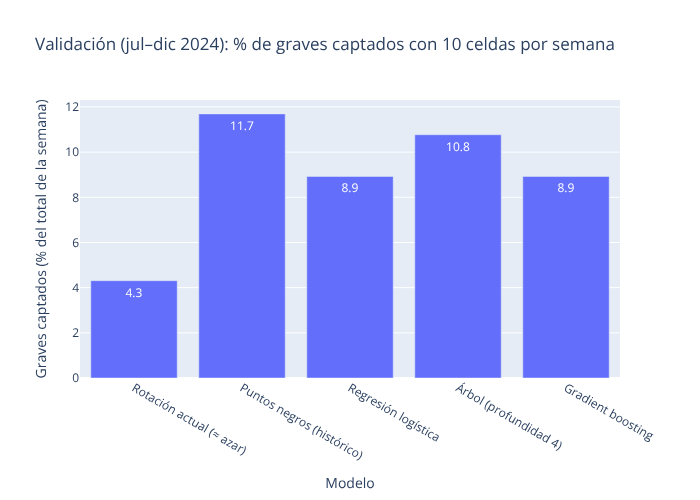

In [9]:
def make_pipe(model, num=NUM, cat=CAT, scale=False):
    num_t = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]) if scale else SimpleImputer(strategy="median")
    pre = ColumnTransformer([("num", num_t, list(num)), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat))])
    return Pipeline([("pre", pre), ("model", model)])

models = {
    "Regresión logística": make_pipe(LogisticRegression(C=0.5, max_iter=2000, random_state=SEED), scale=True),
    "Árbol (profundidad 4)": make_pipe(DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=SEED)),
    "Gradient boosting": make_pipe(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)),
}
X_cols = NUM + CAT
res = {"Rotación actual (≈ azar)": evaluate(val, azar), "Puntos negros (histórico)": evaluate(val, regla)}
for name, pipe in models.items():
    pipe.fit(train[X_cols], train.y)
    res[name] = evaluate(val, pipe.predict_proba(val[X_cols])[:, 1])
comp = pd.DataFrame(res).T
display(comp)
fig = px.bar(comp.reset_index(), x="index", y=f"captura@{TOP_K} (%)", text_auto=".1f",
             title=f"Validación (jul–dic 2024): % de graves captados con {TOP_K} celdas por semana",
             labels={"index": "Modelo", f"captura@{TOP_K} (%)": "Graves captados (% del total de la semana)"})
fig.show()

In [10]:
# Ablación: ¿qué grupos de variables aportan? (gradient boosting, validación)
gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)
variantes = {
    "Todas las variables": (NUM, CAT),
    "Sin calendario (mes, agosto)": ([c for c in NUM if c not in ("mes", "es_agosto")], CAT),
    "Sin historial largo (26 s e histórico)": ([c for c in NUM if c not in ("graves_26s", "tasa_hist")], CAT),
    "Sin distrito": (NUM, [c for c in CAT if c != "cod_distrito"]),
    "Solo identidad de la celda": ([], CAT),
}
ab = {}
for nombre, (n_, c_) in variantes.items():
    p = make_pipe(clone(gb), num=n_, cat=c_)
    p.fit(train[n_ + c_], train.y)
    ab[nombre] = evaluate(val, p.predict_proba(val[n_ + c_])[:, 1])
display(pd.DataFrame(ab).T)

,AP,AUC,captura@10 (%),precisión@10 (%)
Todas las variables,0.074,0.704,8.923,9.259
"Sin calendario (mes, agosto)",0.073,0.703,9.231,10.000
Sin historial largo (26 s e histórico),0.076,0.702,9.538,8.889
Sin distrito,0.074,0.711,8.923,9.259
Solo identidad de la celda,0.074,0.707,9.846,9.630


In [11]:
mejor_val = comp.drop(["Rotación actual (≈ azar)", "Puntos negros (histórico)"])[f"captura@{TOP_K} (%)"].idxmax()
regla_c = comp.loc["Puntos negros (histórico)", f"captura@{TOP_K} (%)"]
mejor_c = comp.loc[mejor_val, f"captura@{TOP_K} (%)"]
display(Markdown(f"### Qué significa para el planificador\nEn la validación, el mejor candidato es **{mejor_val}**, que capta el **{mejor_c:.1f} %** de los heridos graves con 10 celdas por semana, frente al **{regla_c:.1f} %** de la regla de puntos negros. "
                 + ("Es una mejora visible, pero con unas pocas semanas de validación todavía puede deberse al azar; la sección 8 lo comprueba con varios tramos de tiempo y con la prueba final." if mejor_c > regla_c
                    else "El modelo no supera todavía a la regla de puntos negros en validación: es un resultado válido y se discute con honestidad en las secciones 8 y 11.")))

### Qué significa para el planificador
En la validación, el mejor candidato es **Árbol (profundidad 4)**, que capta el **10.8 %** de los heridos graves con 10 celdas por semana, frente al **11.7 %** de la regla de puntos negros. El modelo no supera todavía a la regla de puntos negros en validación: es un resultado válido y se discute con honestidad en las secciones 8 y 11.

## 7. Métrica y coste de los errores

**Por qué captura@10.** La plantilla cubre 10 combinaciones por semana, no "las que superen un umbral". Es un ranking con tope fijo, así que la métrica natural es qué parte de los graves cae en esas 10 celdas; la **precisión@10** dice cuántas de ellas tuvieron algún grave. El **AP** solo sirve para comparar y ajustar, porque no depende del umbral y funciona con clases muy desequilibradas (Saito y Rehmsmeier, 2015). La exactitud se descarta: decir siempre "no" ya acertaría más del 95 %.

**Los errores no cuestan igual.** Una *falsa alarma* es un control sin accidente grave esa semana: gasta horas de agentes, pero la prevención no deja rastro cuando funciona. Un *falso negativo* es una oportunidad perdida. Como el tope es fijo, cada celda añadida deja otra fuera, y por eso el umbral es un número de celdas (K = 10) y no una probabilidad.

,Con graves esa semana,Sin graves esa semana
Celda elegida (control),27,243
Celda no elegida,259,8543


De cada 10 celdas elegidas, 1.0 tuvieron al menos un grave; quedaron fuera 259 celdas-semana con graves (el 91 % de las celdas con graves).


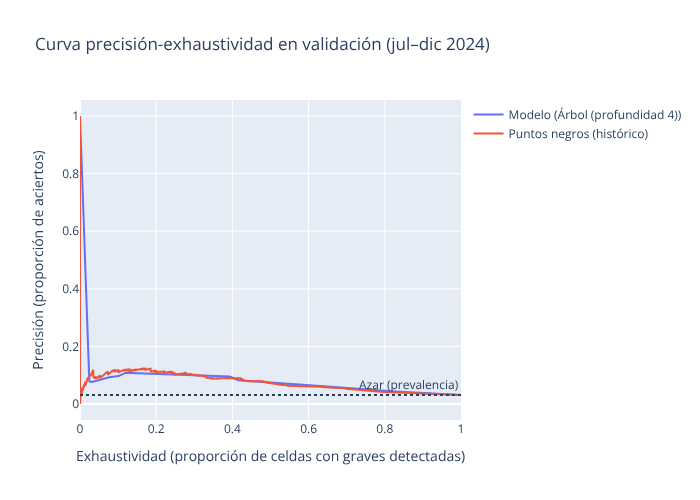

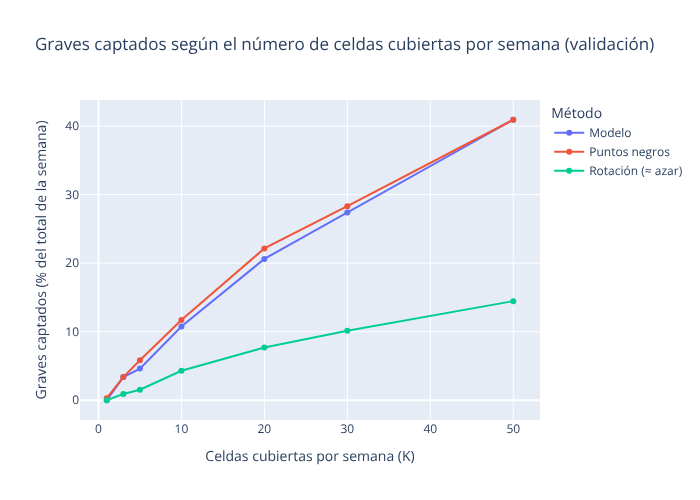

franja,00-06,06-12,12-18,18-24
tipo_dia,,,,
D,12,9,14,8
L-J,17,40,35,52
S,14,12,12,11
V,5,15,17,17


In [12]:
final_name_prelim = mejor_val   # mejor candidato en validación; solo ilustra esta sección (la elección formal se hace en la sección 8)
pipe_v = clone(models[final_name_prelim]).fit(train[X_cols], train.y)
s_val = pipe_v.predict_proba(val[X_cols])[:, 1]

# (a) Matriz de confusión del "top-10" en validación, en términos de negocio
sel = (week_rank(val, s_val) < TOP_K).values
tp = int((sel & (val.y == 1)).sum()); fp = int((sel & (val.y == 0)).sum())
fn = int((~sel & (val.y == 1)).sum()); tn = int((~sel & (val.y == 0)).sum())
cm = pd.DataFrame({"Con graves esa semana": [tp, fn], "Sin graves esa semana": [fp, tn]},
                  index=["Celda elegida (control)", "Celda no elegida"])
display(cm)
print(f"De cada 10 celdas elegidas, {tp / (tp + fp) * 10:.1f} tuvieron al menos un grave; "
      f"quedaron fuera {fn} celdas-semana con graves (el {fn / (tp + fn) * 100:.0f} % de las celdas con graves).")

# (b) Curva precisión-exhaustividad: modelo frente a la regla de puntos negros
fig = go.Figure()
for nombre, sc in {f"Modelo ({final_name_prelim})": s_val, "Puntos negros (histórico)": regla}.items():
    p, r, _ = precision_recall_curve(val.y, sc)
    fig.add_trace(go.Scatter(x=r, y=p, mode="lines", name=nombre))
fig.add_hline(y=val.y.mean(), line_dash="dot", annotation_text="Azar (prevalencia)")
fig.update_layout(title="Curva precisión-exhaustividad en validación (jul–dic 2024)",
                  xaxis_title="Exhaustividad (proporción de celdas con graves detectadas)", yaxis_title="Precisión (proporción de aciertos)")
fig.show()

# (c) ¿Qué pasa si se pueden cubrir más o menos celdas? captura según K
ks = [1, 3, 5, 10, 20, 30, 50]
curva = []
for k in ks:
    for nombre, sc in {"Modelo": s_val, "Puntos negros": regla, "Rotación (≈ azar)": azar}.items():
        pw = topk_weekly(val, sc, k)
        curva.append({"K": k, "Método": nombre, "captura": pw.graves_sel.sum() / pw.graves_total.sum() * 100})
fig = px.line(pd.DataFrame(curva), x="K", y="captura", color="Método", markers=True,
              title="Graves captados según el número de celdas cubiertas por semana (validación)",
              labels={"K": "Celdas cubiertas por semana (K)", "captura": "Graves captados (% del total de la semana)"})
fig.show()

# (d) Dónde caen los errores grandes: graves en celdas no elegidas, por franja y tipo de día
miss = val[~sel & (val.graves > 0)]
display(miss.groupby(["tipo_dia", "franja"]).graves.sum().unstack(fill_value=0))

### Qué significa para el planificador
La tabla de confusión se lee así: de las 10 celdas que el modelo propone cada semana, solo una parte tendrá un herido grave esa misma semana. Eso es esperable, porque los graves son raros y aleatorios, y no significa que el control "no sirviera". Lo que importa es que **con el mismo personal se cubren más graves** que con la regla de puntos negros. La gráfica de K enseña además cuánto se ganaría si se pudiera cubrir una celda más o una menos.

## 8. Validación y ajuste

Validación cruzada con **ventanas crecientes por semanas** (cuatro tramos sobre 2023–2024), búsqueda en rejilla del gradient boosting puntuando por AP y comparación con la logística. La elección del modelo final es explícita: **gana el más simple salvo que el gradient boosting lo supere en más de 0,005 de AP medio**. Después, **una sola evaluación en 2025**, con intervalo de confianza *bootstrap* por semanas para la diferencia con la regla de puntos negros. El sobreajuste se mira comparando AP de entrenamiento y de validación cruzada.

Tramos: [(13440, 3360), (16800, 3360), (20160, 3360), (23520, 3360)] (filas de entrenamiento, filas de validación)


Búsqueda terminada en 11 s. Mejores parámetros: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__max_iter': 200}


,params,mean_test_score,std_test_score
7,"{'model__learning_rate': 0.1, 'model__max_dept...",0.083,0.011
6,"{'model__learning_rate': 0.1, 'model__max_dept...",0.083,0.010
1,"{'model__learning_rate': 0.03, 'model__max_dep...",0.083,0.010
0,"{'model__learning_rate': 0.03, 'model__max_dep...",0.083,0.011
9,"{'model__learning_rate': 0.1, 'model__max_dept...",0.081,0.016
8,"{'model__learning_rate': 0.1, 'model__max_dept...",0.081,0.016


,modelo,tramo,AP,AP en entrenamiento,captura@10 (%),captura regla (%)
0,Regresión logística,1,0.088,0.106,7.143,15.179
1,Regresión logística,2,0.074,0.105,9.346,12.150
2,Regresión logística,3,0.099,0.099,8.271,14.286
3,Regresión logística,4,0.068,0.099,10.345,9.483
0,Gradient boosting ajustado,1,0.094,0.139,12.500,15.179
1,Gradient boosting ajustado,2,0.073,0.129,11.215,12.150
2,Gradient boosting ajustado,3,0.093,0.104,9.774,14.286
3,Gradient boosting ajustado,4,0.072,0.110,9.483,9.483


AP       AP en entrenamiento        \
                            mean   std                mean   std   
modelo                                                             
Gradient boosting ajustado 0.083 0.012               0.120 0.016   
Regresión logística        0.082 0.014               0.102 0.004   

                           captura@10 (%)       captura regla (%)        
                                     mean   std              mean   std  
modelo                                                                   
Gradient boosting ajustado         10.743 1.395            12.774 2.536  
Regresión logística                 8.776 1.379            12.774 2.536

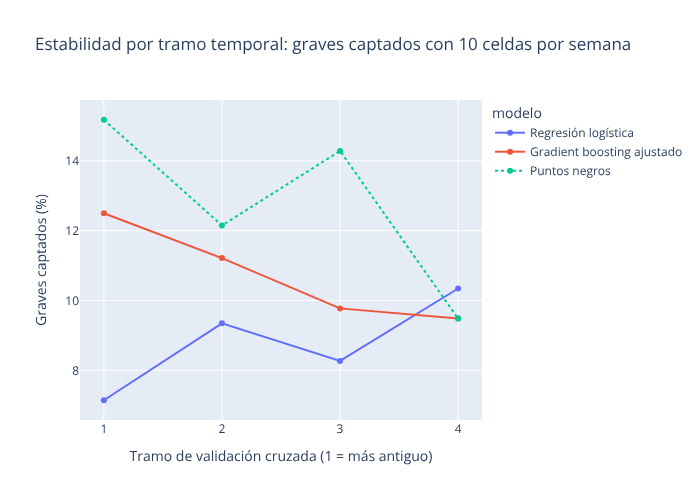

AP medio: logística 0.082 | gradient boosting 0.083  ->  modelo elegido: Regresión logística


In [13]:
dev_w = np.sort(dev.semana.unique()); n_w = len(dev_w)
folds = []
for i in range(4):
    c0, c1 = int(n_w * (0.5 + 0.125 * i)), int(n_w * (0.5 + 0.125 * (i + 1)))
    tr = np.where(dev.semana.isin(dev_w[:c0]))[0]; te = np.where(dev.semana.isin(dev_w[c0:c1]))[0]
    folds.append((tr, te))
print("Tramos:", [(len(a), len(b)) for a, b in folds], "(filas de entrenamiento, filas de validación)")

grid = {"model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3, 4], "model__max_iter": [100, 200]}
t0 = time.time()
search = GridSearchCV(make_pipe(HistGradientBoostingClassifier(random_state=SEED)), grid, scoring="average_precision",
                      cv=folds, n_jobs=1, refit=True)
search.fit(dev[X_cols], dev.y)
print(f"Búsqueda terminada en {time.time() - t0:.0f} s. Mejores parámetros: {search.best_params_}")
display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).head(6))

best_gb = search.best_estimator_
lr = models["Regresión logística"]

def fold_table(pipe, name):
    out = []
    for i, (tr, te) in enumerate(folds):
        m = clone(pipe).fit(dev.iloc[tr][X_cols], dev.iloc[tr].y)
        sc = m.predict_proba(dev.iloc[te][X_cols])[:, 1]
        e = evaluate(dev.iloc[te].reset_index(drop=True), sc)
        e_r = evaluate(dev.iloc[te].reset_index(drop=True), dev.iloc[te]["tasa_hist"].values)
        e_tr = average_precision_score(dev.iloc[tr].y, m.predict_proba(dev.iloc[tr][X_cols])[:, 1])
        out.append({"modelo": name, "tramo": i + 1, "AP": e["AP"], "AP en entrenamiento": e_tr,
                    f"captura@{TOP_K} (%)": e[f"captura@{TOP_K} (%)"], f"captura regla (%)": e_r[f"captura@{TOP_K} (%)"]})
    return pd.DataFrame(out)

cv_all = pd.concat([fold_table(lr, "Regresión logística"), fold_table(best_gb, "Gradient boosting ajustado")])
display(cv_all.round(3))
cv_mean = cv_all.groupby("modelo")[["AP", "AP en entrenamiento", f"captura@{TOP_K} (%)", "captura regla (%)"]].agg(["mean", "std"]).round(3)
display(cv_mean)

fig = px.line(cv_all, x="tramo", y=f"captura@{TOP_K} (%)", color="modelo", markers=True,
              title="Estabilidad por tramo temporal: graves captados con 10 celdas por semana",
              labels={"tramo": "Tramo de validación cruzada (1 = más antiguo)", f"captura@{TOP_K} (%)": "Graves captados (%)"})
reg_line = cv_all[cv_all.modelo == "Regresión logística"]
fig.add_trace(go.Scatter(x=reg_line.tramo, y=reg_line["captura regla (%)"], mode="lines+markers", name="Puntos negros", line=dict(dash="dot")))
fig.show()

ap_gb = cv_all[cv_all.modelo == "Gradient boosting ajustado"].AP.mean(); ap_lr = cv_all[cv_all.modelo == "Regresión logística"].AP.mean()
if ap_gb > ap_lr + 0.005:
    final_name, final_pipe = "Gradient boosting ajustado", clone(best_gb)
else:
    final_name, final_pipe = "Regresión logística", clone(lr)
print(f"AP medio: logística {ap_lr:.3f} | gradient boosting {ap_gb:.3f}  ->  modelo elegido: {final_name}")

,AP,AUC,captura@10 (%),precisión@10 (%)
Modelo (Regresión logística),0.077,0.753,13.906,10.962
Puntos negros (histórico),0.067,0.726,10.225,8.269
Rotación (≈ azar),0.026,0.500,2.454,2.115


Diferencia de captura modelo - regla: +3.7 puntos (IC 95 %: +1.1 a +6.4). Equivale a +18.0 heridos graves más cubiertos al año.


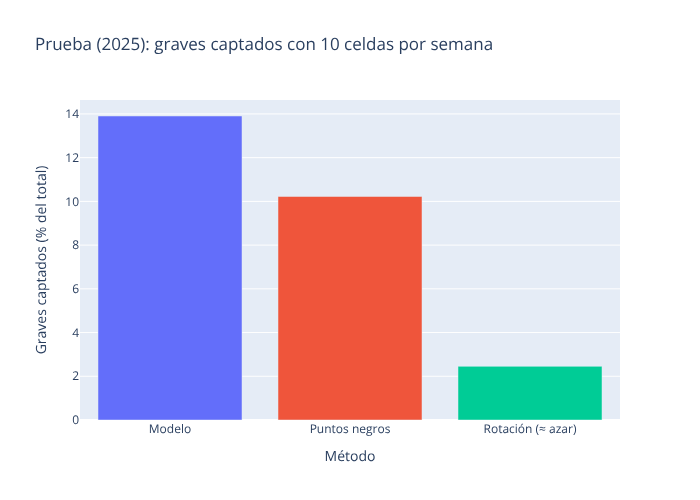

In [14]:
# ---- ÚNICA evaluación en la prueba (2025) ----
final_pipe.fit(dev[X_cols], dev.y)
s_test = final_pipe.predict_proba(test[X_cols])[:, 1]
r_test = test["tasa_hist"].values
pw_m, pw_r, pw_a = topk_weekly(test, s_test), topk_weekly(test, r_test), topk_weekly(test, np.zeros(len(test)))

tabla_test = pd.DataFrame({
    f"Modelo ({final_name})": evaluate(test, s_test),
    "Puntos negros (histórico)": evaluate(test, r_test),
    "Rotación (≈ azar)": evaluate(test, np.zeros(len(test))),
}).T
display(tabla_test)

# Bootstrap por semanas de la diferencia de captura (modelo - regla)
rng = np.random.default_rng(SEED)
W = len(pw_m); diffs = []
for _ in range(2000):
    idx = rng.integers(0, W, W)
    diffs.append(pw_m.graves_sel.values[idx].sum() / pw_m.graves_total.values[idx].sum()
                 - pw_r.graves_sel.values[idx].sum() / pw_r.graves_total.values[idx].sum())
ic_lo, ic_hi = np.percentile(diffs, [2.5, 97.5]) * 100
dif_media = (pw_m.graves_sel.sum() / pw_m.graves_total.sum() - pw_r.graves_sel.sum() / pw_r.graves_total.sum()) * 100
extra_year = (pw_m.graves_sel.sum() - pw_r.graves_sel.sum()) / W * 52
print(f"Diferencia de captura modelo - regla: {dif_media:+.1f} puntos (IC 95 %: {ic_lo:+.1f} a {ic_hi:+.1f}). "
      f"Equivale a {extra_year:+.1f} heridos graves más cubiertos al año.")

fig = go.Figure()
for nombre, pw in {"Modelo": pw_m, "Puntos negros": pw_r, "Rotación (≈ azar)": pw_a}.items():
    fig.add_trace(go.Bar(name=nombre, x=[nombre], y=[pw.graves_sel.sum() / pw.graves_total.sum() * 100]))
fig.update_layout(title="Prueba (2025): graves captados con 10 celdas por semana", yaxis_title="Graves captados (% del total)", xaxis_title="Método", showlegend=False)
fig.show()

In [15]:
gap_ap = cv_all.groupby("modelo")[["AP en entrenamiento", "AP"]].mean()
gap_ap["diferencia"] = gap_ap["AP en entrenamiento"] - gap_ap["AP"]
display(gap_ap.round(3))
mejora_clara = ic_lo > 0
cv_f = cv_all[cv_all.modelo == final_name]
cv_mod, cv_reg = cv_f[f"captura@{TOP_K} (%)"].mean(), cv_f["captura regla (%)"].mean()
cv_ok = cv_mod >= cv_reg          # ¿la validación cruzada 2023-2024 apunta en la misma dirección?
display(Markdown("### Qué significa para el planificador\n"
    f"Con el modelo elegido (**{final_name}**), usando 2025 como prueba que no se había tocado, las 10 celdas propuestas cada semana captan el "
    f"**{pw_m.graves_sel.sum() / pw_m.graves_total.sum() * 100:.1f} %** de los heridos graves, frente al **{pw_r.graves_sel.sum() / pw_r.graves_total.sum() * 100:.1f} %** de la regla de puntos negros "
    f"(diferencia de **{dif_media:+.1f} puntos**, intervalo de confianza del 95 %: {ic_lo:+.1f} a {ic_hi:+.1f}). "
    + ("El intervalo no incluye el cero en 2025. " if mejora_clara else "El intervalo incluye el cero: **no se puede afirmar** que el modelo mejore a la regla de puntos negros en 2025. ")
    + f"Pero en la validación cruzada de 2023-2024 el modelo capta de media el **{cv_mod:.1f} %** frente al **{cv_reg:.1f} %** de los puntos negros. "
    + ("Las dos pruebas coinciden." if (cv_ok == mejora_clara) else "**Las dos pruebas no coinciden:** la evidencia es mixta y la diferencia depende del periodo. No conviene presentar la mejora como segura.")
    + " Además, con 10 celdas el modelo capta menos de una de cada siete graves (sección 7): ayuda a ordenar, no a predecir."))

,AP en entrenamiento,AP,diferencia
modelo,,,
Gradient boosting ajustado,0.120,0.083,0.037
Regresión logística,0.102,0.082,0.020


### Qué significa para el planificador
Con el modelo elegido (**Regresión logística**), usando 2025 como prueba que no se había tocado, las 10 celdas propuestas cada semana captan el **13.9 %** de los heridos graves, frente al **10.2 %** de la regla de puntos negros (diferencia de **+3.7 puntos**, intervalo de confianza del 95 %: +1.1 a +6.4). El intervalo no incluye el cero en 2025. Pero en la validación cruzada de 2023-2024 el modelo capta de media el **8.8 %** frente al **12.8 %** de los puntos negros. **Las dos pruebas no coinciden:** la evidencia es mixta y la diferencia depende del periodo. No conviene presentar la mejora como segura. Además, con 10 celdas el modelo capta menos de una de cada siete graves (sección 7): ayuda a ordenar, no a predecir.

## 9. Interpretación

Uso la **importancia por permutación**: desordeno una variable cada vez en datos de validación y mido cuánto cae el AP. Se calcula sobre las variables originales del pipeline, con el modelo entrenado solo en el periodo de entrenamiento, para no tocar la prueba. Después explico **tres predicciones** por *oclusión*: sustituyo cada variable de la celda por su valor típico y miro cuánto baja la probabilidad.

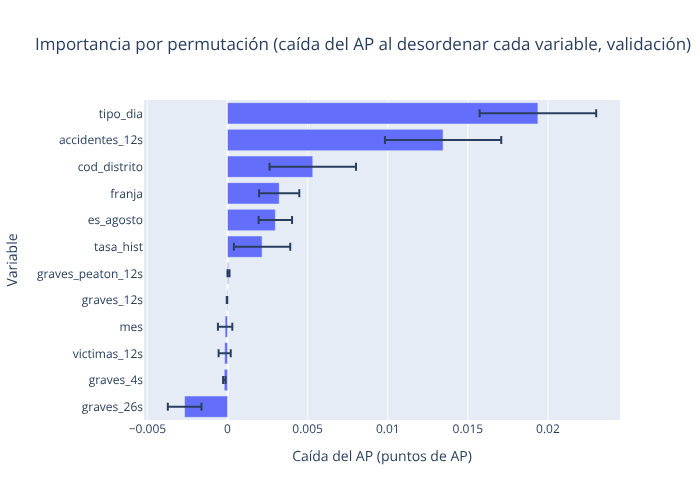

Variables más importantes: ['tipo_dia', 'accidentes_12s', 'cod_distrito', 'franja', 'es_agosto']


In [16]:
pi_model = clone(final_pipe).fit(train[X_cols], train.y)
pi = permutation_importance(pi_model, val[X_cols], val.y, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"variable": X_cols, "importancia": pi.importances_mean, "desv": pi.importances_std}).sort_values("importancia")
fig = px.bar(imp, x="importancia", y="variable", orientation="h", error_x="desv",
             title="Importancia por permutación (caída del AP al desordenar cada variable, validación)",
             labels={"importancia": "Caída del AP (puntos de AP)", "variable": "Variable"})
fig.show()
top_vars = imp.sort_values("importancia", ascending=False).head(5).variable.tolist()
print("Variables más importantes:", top_vars)

In [17]:
# Tres predicciones explicadas sobre la prueba, con el modelo final ya ajustado
base_vals = {c: train[c].median() for c in NUM} | {c: train[c].mode()[0] for c in CAT}
t = test.assign(score=s_test)
casos = {
    "Acierto: celda con graves y puntuación más alta": t[t.y == 1].sort_values("score", ascending=False).iloc[0],
    "Falsa alarma: celda sin graves y puntuación más alta": t[t.y == 0].sort_values("score", ascending=False).iloc[0],
    "Fallo: celda con graves y puntuación más baja": t[t.y == 1].sort_values("score").iloc[0],
}
for titulo, fila in casos.items():
    x0 = fila[X_cols].to_frame().T.astype({c: float for c in NUM})
    p0 = final_pipe.predict_proba(x0)[0, 1]
    efecto = {}
    for c in X_cols:
        x1 = x0.copy(); x1[c] = base_vals[c]
        efecto[c] = p0 - final_pipe.predict_proba(x1)[0, 1]
    top = sorted(efecto.items(), key=lambda kv: -abs(kv[1]))[:3]
    print(f"\n{titulo}\n  semana {fila.semana.date()} · distrito {fila.cod_distrito} · {fila.tipo_dia} · franja {fila.franja} · graves reales: {int(fila.graves)} · probabilidad prevista: {p0:.1%}")
    for c, v in top:
        print(f"    - {c} = {fila[c]}: aporta {v:+.1%} a la probabilidad")


Acierto: celda con graves y puntuación más alta
  semana 2025-12-15 · distrito 4 · L-J · franja 12-18 · graves reales: 1 · probabilidad prevista: 20.5%
    - tipo_dia = L-J: aporta +13.6% a la probabilidad
    - accidentes_12s = 108.0: aporta +13.6% a la probabilidad
    - graves_26s = 7.0: aporta -8.7% a la probabilidad

Falsa alarma: celda sin graves y puntuación más alta
  semana 2025-12-15 · distrito 13 · L-J · franja 12-18 · graves reales: 0 · probabilidad prevista: 24.2%
    - tipo_dia = L-J: aporta +15.9% a la probabilidad
    - accidentes_12s = 92.0: aporta +14.1% a la probabilidad
    - franja = 12-18: aporta +9.7% a la probabilidad

Fallo: celda con graves y puntuación más baja
  semana 2025-08-25 · distrito 21 · S · franja 18-24 · graves reales: 1 · probabilidad prevista: 0.4%
    - cod_distrito = 21: aporta -1.2% a la probabilidad
    - es_agosto = 1: aporta -0.3% a la probabilidad
    - franja = 18-24: aporta +0.2% a la probabilidad


In [18]:
display(Markdown("### Qué significa para el planificador\n"
    f"Las variables que más pesan en el modelo son: **{', '.join(top_vars[:3])}**. "
    + ("Destacan `accidentes_12s` o `victimas_12s`: el modelo mide sobre todo **exposición** (dónde y cuándo hay muchos accidentes), no un riesgo de gravedad distinto del volumen de tráfico. " if any(v in top_vars[:3] for v in ("accidentes_12s", "victimas_12s")) else "")
    + ("Pesan `tipo_dia` o `franja`: el momento de la semana importa, como apuntaba H1; conviene contrastarlo con la tabla de hipótesis, que decide si esa idea se sostiene. " if any(v in top_vars[:3] for v in ("tipo_dia", "franja")) else "")
    + ("Pesa el distrito: hay lugares con más riesgo por sí mismos. " if "cod_distrito" in top_vars[:3] else "")
    + ("El historial de graves (`graves_*`, `tasa_hist`) pesa mucho: el modelo sigue a los puntos negros conocidos. " if any(v.startswith("graves_") or v == "tasa_hist" for v in top_vars[:3]) else "")
    + "Las variables con importancia casi nula (revisa la gráfica) se podrían retirar sin perder calidad."))

### Qué significa para el planificador
Las variables que más pesan en el modelo son: **tipo_dia, accidentes_12s, cod_distrito**. Destacan `accidentes_12s` o `victimas_12s`: el modelo mide sobre todo **exposición** (dónde y cuándo hay muchos accidentes), no un riesgo de gravedad distinto del volumen de tráfico. Pesan `tipo_dia` o `franja`: el momento de la semana importa, como apuntaba H1; conviene contrastarlo con la tabla de hipótesis, que decide si esa idea se sostiene. Pesa el distrito: hay lugares con más riesgo por sí mismos. Las variables con importancia casi nula (revisa la gráfica) se podrían retirar sin perder calidad.

## 10. Equidad, ética y riesgos

**Entre grupos.** Comparo, por distrito, franja y semestre, qué parte de los graves de 2025 caía en las celdas elegidas por el modelo y por la regla de puntos negros. Concentrar los controles en pocos distritos puede ser eficaz en el papel y dejar zonas con riesgo real sin cobertura.

**Datos personales.** El dataset es abierto y sin nombres, pero cada fila describe a una persona y las coordenadas pueden reidentificar un accidente. **Mitigación:** el modelo no usa edad, sexo, coordenadas ni alcohol/drogas, solo recuentos por celda; el dashboard publicará agregados con mínimo de 10 casos, como fija el brief.

**Si el modelo se equivoca.**
- *Falso negativo:* una zona sin refuerzo donde luego hay un grave. Pagan los usuarios vulnerables (peatones mayores, motoristas).
- *Falsa alarma:* controles sin incidentes. Pagan los conductores de la zona y el coste de agentes.
- *Sesgo de registro y realimentación:* los datos reflejan dónde hay agentes; más controles dan más positivos registrados y el modelo ve más riesgo. Por eso el KPI principal es la gravedad, no los positivos.
- *Uso indebido:* el modelo habla de sitios y momentos, nunca de personas.

,graves (n.º),% graves de la ciudad,cubiertos modelo (%),cubiertos regla (%),veces elegido (modelo)
5,43.000,8.800,37.200,32.600,120.000
4,39.000,8.000,61.500,33.300,125.000
15,31.000,6.300,22.600,3.200,60.000
9,29.000,5.900,0.000,0.000,3.000
11,28.000,5.700,0.000,0.000,0.000
7,28.000,5.700,0.000,0.000,0.000
2,28.000,5.700,3.600,21.400,1.000
13,28.000,5.700,28.600,28.600,113.000
6,27.000,5.500,0.000,0.000,0.000
1,26.000,5.300,19.200,11.500,40.000


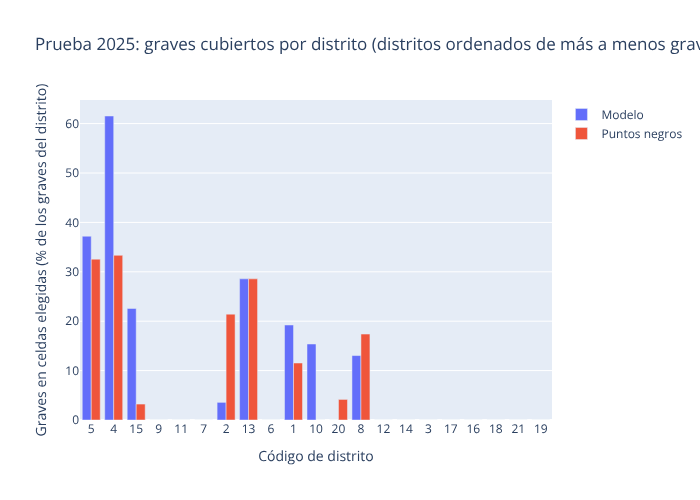

,graves (n.º),cubiertos modelo (%),cubiertos regla (%)
00-06,56.000,0.000,0.000
06-12,144.000,5.600,8.300
12-18,157.000,25.500,17.200
18-24,132.000,15.200,8.300


,graves (n.º),cubiertos modelo (%),cubiertos regla (%)
ene–jun 2025,235.000,13.600,9.800
jul–dic 2025,254.000,14.200,10.600


### Qué significa para el planificador
En 2025 el modelo eligió celdas de **11 de 21 distritos**, y **47 %** de las elecciones se concentraron en dos (códigos 4, 5). Hay distritos con una parte relevante de los graves que **nunca** entraron en el top-10: 11, 7, 6, 12, 14, 17, 16. Esto es un riesgo de desatender zonas; se recomienda reservar parte de la capacidad a una cobertura mínima por distrito. Antes de usar el ranking como única guía conviene que la unidad lo cruce con su conocimiento del terreno.

In [19]:
test_sel_m = (week_rank(test, s_test) < TOP_K).values
test_sel_r = (week_rank(test, r_test) < TOP_K).values
t = test.assign(sel_m=test_sel_m, sel_r=test_sel_r)

def cobertura(g):
    tot = g.graves.sum()
    return pd.Series({"graves (n.º)": tot, "% graves de la ciudad": np.nan,
                      "cubiertos modelo (%)": g[g.sel_m].graves.sum() / tot * 100 if tot else np.nan,
                      "cubiertos regla (%)": g[g.sel_r].graves.sum() / tot * 100 if tot else np.nan,
                      "veces elegido (modelo)": int(g.sel_m.sum())})

by = lambda col: pd.DataFrame({k: cobertura(g) for k, g in t.groupby(col)}).T
por_dist = by("cod_distrito")
por_dist["% graves de la ciudad"] = por_dist["graves (n.º)"] / por_dist["graves (n.º)"].sum() * 100
por_dist = por_dist.sort_values("graves (n.º)", ascending=False)
display(por_dist.round(1).head(21))

fig = go.Figure()
fig.add_bar(x=por_dist.index.astype(str), y=por_dist["cubiertos modelo (%)"], name="Modelo")
fig.add_bar(x=por_dist.index.astype(str), y=por_dist["cubiertos regla (%)"], name="Puntos negros")
fig.update_layout(barmode="group", title="Prueba 2025: graves cubiertos por distrito (distritos ordenados de más a menos graves)",
                  xaxis_title="Código de distrito", yaxis_title="Graves en celdas elegidas (% de los graves del distrito)")
fig.show()

por_franja = by("franja")[["graves (n.º)", "cubiertos modelo (%)", "cubiertos regla (%)"]]
display(por_franja.round(1))
t["semestre"] = np.where(t.semana.dt.month <= 6, "ene–jun 2025", "jul–dic 2025")
display(by("semestre")[["graves (n.º)", "cubiertos modelo (%)", "cubiertos regla (%)"]].round(1))

sin_cobertura = por_dist[(por_dist["% graves de la ciudad"] >= 3) & (por_dist["veces elegido (modelo)"] == 0)]
n_dist_elegidos = int((por_dist["veces elegido (modelo)"] > 0).sum())
sel_d = por_dist["veces elegido (modelo)"].sort_values(ascending=False)
top2_share = sel_d.head(2).sum() / sel_d.sum() * 100
top2_names = ", ".join(map(str, sel_d.head(2).index))
display(Markdown("### Qué significa para el planificador\n"
    f"En 2025 el modelo eligió celdas de **{n_dist_elegidos} de {len(por_dist)} distritos**, y **{top2_share:.0f} %** de las elecciones se concentraron en dos (códigos {top2_names}). "
    + (f"Hay distritos con una parte relevante de los graves que **nunca** entraron en el top-10: {', '.join(map(str, sin_cobertura.index))}. Esto es un riesgo de desatender zonas; se recomienda reservar parte de la capacidad a una cobertura mínima por distrito. "
       if len(sin_cobertura) else "Ningún distrito con una parte importante de los graves quedó sin cobertura, aunque la cobertura no es uniforme (ver tabla). ")
    + "Antes de usar el ranking como única guía conviene que la unidad lo cruce con su conocimiento del terreno."))

## 11. Recomendación

**Qué hacer.** Usar el ranking semanal como **ayuda para ordenar candidatas**, no como orden: el modelo propone dónde mirar y la unidad decide el tipo de control con H1–H3.

**Mejora esperada.** La celda siguiente traduce la diferencia con la regla de puntos negros a graves cubiertos por año. Es una cota de *cobertura*, no de prevención: que un grave ocurra en una celda controlada no prueba que el control lo evite.

**Cuándo no fiarse.** Si cambia el esquema del fichero o el criterio de registro de la lesividad; con eventos que alteran el tráfico (obras, grandes eventos, nueva normativa de velocidad); si el intervalo de la sección 8 incluye el cero; y siempre para decisiones sobre personas.

**Bloque 4.** Despliegue en Streamlit con la construcción de variables incluida; monitorización con los datos de 2026 (deriva y captura@10 semanal frente a la regla); reentrenamiento mensual; y unir previsión del tiempo, festivos y padrón.

In [20]:
cap_m = pw_m.graves_sel.sum() / pw_m.graves_total.sum() * 100
cap_r = pw_r.graves_sel.sum() / pw_r.graves_total.sum() * 100
cap_a = pw_a.graves_sel.sum() / pw_a.graves_total.sum() * 100
graves_ano = pw_m.graves_total.sum() / W * 52
adoptar = mejora_clara and cv_ok
display(Markdown("### Qué significa para el planificador\n"
    f"En 2025 hubo unos **{graves_ano:.0f} heridos graves o fallecidos al año** en el conjunto de celdas modelizadas (los registrados por la Policía Municipal). "
    f"La rotación actual (simulada con el azar) captaría el {cap_a:.1f} % de ellos, la regla de puntos negros el {cap_r:.1f} % y el modelo el {cap_m:.1f} %. "
    f"La diferencia modelo–regla son **{dif_media:+.1f} puntos**, unos **{extra_year:+.1f} heridos graves más dentro de las zonas controladas al año** (IC 95 % de la diferencia: {ic_lo:+.1f} a {ic_hi:+.1f} puntos). "
    + (f"La rotación actual y los puntos negros se mantienen como referencia. " )
    + ("Las dos pruebas (2025 y validación cruzada) coinciden, así que la recomendación es **adoptar el ranking como apoyo** y comprobar en el bloque 4 que se mantiene en 2026." if adoptar
       else "La evidencia es **mixta o insuficiente**, así que la recomendación es **no cambiar todavía el procedimiento**: usar el modelo en paralelo, junto a los puntos negros, y decidir con los datos de 2026. ")
    + f" Aviso de equidad: el {top2_share:.0f} % de las elecciones del modelo cae en dos distritos; conviene reservar parte de la plantilla a una cobertura mínima por distrito."))

resumen_0 = f'''
1. **Pregunta:** ¿en qué distritos, días y franjas de 6 horas debe reforzar la unidad de tráfico los controles cada lunes para cubrir más heridos graves con el mismo personal?
2. **Modelo:** {final_name}, entrenado con 2023–2024 con historial de cada celda (distrito × tipo de día × franja) y calendario; se evalúa en 2025 y ordena las 336 celdas de cada semana.
3. **Mejora sobre la regla de puntos negros:** con 10 celdas por semana capta el {cap_m:.1f} % de los graves, frente al {cap_r:.1f} % de ir a los puntos negros y al {cap_a:.1f} % de la rotación actual (azar) (diferencia {dif_media:+.1f} puntos, IC 95 % {ic_lo:+.1f} a {ic_hi:+.1f}).
4. **Qué hacer:** {"usar el ranking semanal como apoyo a la decisión y comprobar la mejora con los datos de 2026" if adoptar else "no cambiar el procedimiento todavía: usar el modelo en paralelo (la evidencia es mixta: en validación cruzada captó " + f"{cv_mod:.1f} % frente a {cv_reg:.1f} % de los puntos negros) y decidir con los datos de 2026"}.
5. **Límite principal:** con 10 celdas el modelo capta solo el {cap_m:.1f} % de los graves (ordena, no predice), el {top2_share:.0f} % de sus elecciones cae en dos distritos, y solo hay tres años completos de registro policial; la mejora mide cobertura, no prevención.
'''
print("=== COPIA ESTO EN LA SECCIÓN 0 ===" + resumen_0)

### Qué significa para el planificador
En 2025 hubo unos **489 heridos graves o fallecidos al año** en el conjunto de celdas modelizadas (los registrados por la Policía Municipal). La rotación actual (simulada con el azar) captaría el 2.5 % de ellos, la regla de puntos negros el 10.2 % y el modelo el 13.9 %. La diferencia modelo–regla son **+3.7 puntos**, unos **+18.0 heridos graves más dentro de las zonas controladas al año** (IC 95 % de la diferencia: +1.1 a +6.4 puntos). La rotación actual y los puntos negros se mantienen como referencia. La evidencia es **mixta o insuficiente**, así que la recomendación es **no cambiar todavía el procedimiento**: usar el modelo en paralelo, junto a los puntos negros, y decidir con los datos de 2026.  Aviso de equidad: el 47 % de las elecciones del modelo cae en dos distritos; conviene reservar parte de la plantilla a una cobertura mínima por distrito.

=== COPIA ESTO EN LA SECCIÓN 0 ===
1. **Pregunta:** ¿en qué distritos, días y franjas de 6 horas debe reforzar la unidad de tráfico los controles cada lunes para cubrir más heridos graves con el mismo personal?
2. **Modelo:** Regresión logística, entrenado con 2023–2024 con historial de cada celda (distrito × tipo de día × franja) y calendario; se evalúa en 2025 y ordena las 336 celdas de cada semana.
3. **Mejora sobre la regla de puntos negros:** con 10 celdas por semana capta el 13.9 % de los graves, frente al 10.2 % de ir a los puntos negros y al 2.5 % de la rotación actual (azar) (diferencia +3.7 puntos, IC 95 % +1.1 a +6.4).
4. **Qué hacer:** no cambiar el procedimiento todavía: usar el modelo en paralelo (la evidencia es mixta: en validación cruzada captó 8.8 % frente a 12.8 % de los puntos negros) y decidir con los datos de 2026.
5. **Límite principal:** con 10 celdas el modelo capta solo el 13.9 % de los graves (ordena, no predice), el 47 % de sus elecciones cae en dos distrito

## 12. Guardado del modelo

Tras cerrar la evaluación, reentreno con **todos los datos (2023–2025)** y guardo con `joblib` un único pipeline en `model.joblib`. Recibe las columnas de variables de cada celda; en el bloque 4, el cálculo del historial (sección 4) pasará a un módulo `.py` para que el dashboard lo genere. Lo recargo y hago una predicción de prueba.

In [21]:
all_data = pd.concat([dev, test]).reset_index(drop=True)
deploy_pipe = clone(final_pipe).fit(all_data[X_cols], all_data.y)
MODEL_PATH = Path("model.joblib")
joblib.dump(deploy_pipe, MODEL_PATH)
print(f"Guardado {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.2f} MB)")

loaded = joblib.load(MODEL_PATH)
ultima = all_data[all_data.semana == all_data.semana.max()]
muestra = ultima.sort_values("tasa_hist", ascending=False).head(1)
p_nuevo = loaded.predict_proba(muestra[X_cols])[:, 1][0]
assert np.allclose(loaded.predict_proba(ultima[X_cols]), deploy_pipe.predict_proba(ultima[X_cols]))
print(f"Predicción de prueba: semana {muestra.semana.iloc[0].date()}, distrito {muestra.cod_distrito.iloc[0]}, "
      f"{muestra.tipo_dia.iloc[0]}, franja {muestra.franja.iloc[0]} -> probabilidad de al menos un grave: {p_nuevo:.1%}")
print("Columnas de entrada del pipeline:", X_cols)
print("Versiones -> python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__, "| joblib", joblib.__version__)

Guardado model.joblib (0.00 MB)
Predicción de prueba: semana 2025-12-29, distrito 5, L-J, franja 12-18 -> probabilidad de al menos un grave: 18.3%
Columnas de entrada del pipeline: ['graves_4s', 'graves_12s', 'graves_26s', 'victimas_12s', 'accidentes_12s', 'graves_peaton_12s', 'tasa_hist', 'mes', 'es_agosto', 'cod_distrito', 'tipo_dia', 'franja']
Versiones -> python 3.13.18 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3 | joblib 1.6.0


### Qué significa para el planificador
El modelo queda guardado en un único archivo, listo para que el bloque 4 lo sirva en el dashboard. Se ha comprobado que, al cargarlo de nuevo, da exactamente las mismas predicciones. Con el tiempo hará falta reentrenarlo cuando lleguen nuevos datos.

## 13. Referencias

Ayuntamiento de Madrid. (2026). *Accidentes de tráfico de la ciudad de Madrid (detalle por persona)* [Conjunto de datos]. Dirección General de la Policía Municipal. Recuperado el 21 de octubre de 2026, de https://datos.madrid.es/dataset/300228-0-accidentes-trafico-detalle

McKinney, W. (2010). Data structures for statistical computing in Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Plotly Technologies Inc. (2015). *Collaborative data science* [Software]. Plotly. https://plot.ly

Saito, T., y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432